# Phase 1: Project scope and target definitions

## Primary research question

Which observable aviation accident factors are most strongly associated with aircraft damage severity?

## Secondary outcomes

This project also prepares binary classification targets for:

- Fatality: whether one or more fatalities were reported.
- Nonfatal injury: whether one or more nonfatal injuries were reported.

These targets describe associations in historical FAA records; they do not establish that a factor caused an accident.

## Target decisions

- Aircraft damage classification uses the `Minor`, `Substantial`, and `Destroyed` categories. Missing and `Unknown` damage values are excluded from that target. The `None` category is excluded for now because it represents no recorded aircraft damage and may require separate interpretation from damage severity.
- Missing predictor values are labeled `Unknown` rather than imputed from unrelated variables.
- The report number is retained for grouped train/test splitting later, but it is not a predictor.
- Multiple rows with the same report number are retained because they may describe different aircraft or pilots involved in one event.


In [1]:
import pandas as pd

df = pd.read_csv("faa_aids_all.csv", low_memory=False)

print("Original Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

exact_duplicates = df.duplicated().sum()

print("\nExact Duplicate Rows:", exact_duplicates)

report_counts = df['rprt_nbr'].value_counts()

print("\nTotal Rows:", len(df))
print("Unique Reports:", df['rprt_nbr'].nunique())

print(
    "Reports Appearing Multiple Times:",
    (report_counts > 1).sum()
)

df_clean = df.drop_duplicates().copy()

print("\nOriginal Rows:", len(df))
print("Rows After Removing Duplicates:", len(df_clean))
print("Rows Removed:", len(df) - len(df_clean))
print("Remaining Exact Duplicates:", df_clean.duplicated().sum())

df_clean['event_lcl_date'] = pd.to_datetime(
    df_clean['event_lcl_date'],
    format='%Y %b %d',
    errors='coerce'
)

print("\nDate Data Type:", df_clean['event_lcl_date'].dtype)
print("Missing Dates:", df_clean['event_lcl_date'].isna().sum())
print("Earliest Event:", df_clean['event_lcl_date'].min())
print("Latest Event:", df_clean['event_lcl_date'].max())

missing_summary = pd.DataFrame({
    'Missing_Count': df_clean.isnull().sum(),
    'Missing_Percentage': (
        df_clean.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values(
    'Missing_Percentage',
    ascending=False
)

print("\nMissing Value Summary:")
display(missing_summary)

damage_counts = df_clean['acft_dmg_code'].value_counts(
    dropna=False
)

damage_summary = pd.DataFrame({
    'Count': damage_counts,
    'Percentage': (
        damage_counts / len(df_clean) * 100
    ).round(2)
})

print("\nAircraft Damage Distribution:")
display(damage_summary)

#selecting the columns directly related to the research question
project_columns = [
    'rprt_nbr',
    'event_type_code',
    'flt_phase_code',
    'pic_cert_type_code',
    'acft_make',
    'acft_model',
    'acft_dmg_code',
    'inj_total_invlvd_fatal_qty',
    'inj_total_invlvd_non_fatal_qty'
]

project_df = df_clean[project_columns].copy()

print("\nProject Dataset Shape:", project_df.shape)

print("\nProject Dataset Preview:")
display(project_df.head())


#create classification labels for injury and fatality outcomes

#fatalities: 0 = None, 1 = One or more
project_df['fatality_class'] = (
    project_df['inj_total_invlvd_fatal_qty']
    .apply(lambda x: 1 if x > 0 else 0 if pd.notna(x) else pd.NA)
    .astype('Int64')
)

#nonfatal injuries: 0 = None, 1 = One or more
project_df['nonfatal_injury_class'] = (
    project_df['inj_total_invlvd_non_fatal_qty']
    .apply(lambda x: 1 if x > 0 else 0 if pd.notna(x) else pd.NA)
    .astype('Int64')
)

print("Fatality Classification:")
display(project_df['fatality_class'].value_counts(dropna=False))

print("\nNonfatal Injury Classification:")
display(project_df['nonfatal_injury_class'].value_counts(dropna=False))

#prepare the three classification targets

#remove rows with missing or unknown aircraft damage
damage_df = project_df[
    project_df['acft_dmg_code'].notna() &
    (project_df['acft_dmg_code'] != 'Unknown')
].copy()

#keep only the three usable damage categories
damage_df = damage_df[
    damage_df['acft_dmg_code'].isin(['Minor', 'Substantial', 'Destroyed'])
]

print("Aircraft Damage Target:")
display(damage_df['acft_dmg_code'].value_counts())

print("\nFatality Target:")
display(project_df['fatality_class'].value_counts(dropna=False))

print("\nNonfatal Injury Target:")
display(project_df['nonfatal_injury_class'].value_counts(dropna=False))

print("\nRows available for damage classification:", len(damage_df))

# prepare the predictor columns for machine learning
feature_columns = [
    'event_type_code',
    'flt_phase_code',
    'pic_cert_type_code',
    'acft_make',
    'acft_model'
]

#prepare the damage classification dataset
damage_model_df = damage_df[
    feature_columns + ['acft_dmg_code', 'rprt_nbr']
].copy()

#prepare the fatality classification dataset
fatality_model_df = project_df[
    feature_columns + ['fatality_class', 'rprt_nbr']
].dropna(subset=['fatality_class']).copy()

#prepare the nonfatal injury classification dataset
nonfatal_model_df = project_df[
    feature_columns + ['nonfatal_injury_class', 'rprt_nbr']
].dropna(subset=['nonfatal_injury_class']).copy()

#replace missing predictor values with "Unknown"
for dataset in [damage_model_df, fatality_model_df, nonfatal_model_df]:
    dataset[feature_columns] = dataset[feature_columns].fillna('Unknown')

print("Damage Classification Rows:", len(damage_model_df))
print("Fatality Classification Rows:", len(fatality_model_df))
print("Nonfatal Injury Classification Rows:", len(nonfatal_model_df))

print("\nPredictor Columns:")
print(feature_columns)

print("\nPrepared Damage Dataset:")
display(damage_model_df.head())

Original Dataset Shape: (251290, 19)

Column Names:
['rprt_nbr', 'event_lcl_date', 'loc_city_name', 'loc_state_code', 'loc_arpt_name', 'event_type_code', 'acft_dmg_code', 'flt_phase_code', 'acft_make', 'acft_model', 'oprtr_code', 'fltcndct_code', 'regist_nbr', 'inj_total_invlvd_fatal_qty', 'inj_total_invlvd_non_fatal_qty', 'eng_make_name', 'eng_model_name', 'eng_grp_mkmd_code', 'pic_cert_type_code']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 251290 entries, 0 to 251289
Data columns (total 19 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   rprt_nbr                        251290 non-null  str    
 1   event_lcl_date                  251290 non-null  str    
 2   loc_city_name                   248945 non-null  str    
 3   loc_state_code                  250370 non-null  str    
 4   loc_arpt_name                   176291 non-null  str    
 5   event_type_code                 2512


Exact Duplicate Rows: 4174

Total Rows: 251290
Unique Reports: 230546
Reports Appearing Multiple Times: 15484



Original Rows: 251290
Rows After Removing Duplicates: 247116
Rows Removed: 4174


Remaining Exact Duplicates: 0

Date Data Type: datetime64[us]
Missing Dates: 0
Earliest Event: 1945-07-23 00:00:00
Latest Event: 2026-10-15 00:00:00



Missing Value Summary:


,Missing_Count,Missing_Percentage
oprtr_code,201725,81.63
pic_cert_type_code,194200,78.59
eng_grp_mkmd_code,162656,65.82
eng_model_name,121281,49.08
eng_make_name,120230,48.65
loc_arpt_name,73795,29.86
acft_dmg_code,40697,16.47
fltcndct_code,28051,11.35
flt_phase_code,6916,2.80
inj_total_invlvd_fatal_qty,5435,2.20


... (13 outputs left out)

nonfatal_injury_class
0       231942
1         9739
<NA>      5435
Name: count, dtype: Int64


Rows available for damage classification: 206105


Damage Classification Rows: 206105
Fatality Classification Rows: 241681
Nonfatal Injury Classification Rows: 241681

Predictor Columns:
['event_type_code', 'flt_phase_code', 'pic_cert_type_code', 'acft_make', 'acft_model']

Prepared Damage Dataset:


,event_type_code,flt_phase_code,pic_cert_type_code,acft_make,acft_model,acft_dmg_code,rprt_nbr
0,Accident,Landing: Touchdown,AIRLINE TRANSPORT,CESSNA,CE-525,Destroyed,20260930012829A
1,Incident,Ground/Ramp/Ma,FLIGHT INSTRUCTOR,ENSTROM HELICOPTER CORP,480,Substantial,20260930013249I
2,Incident,Ground/Ramp/Ma,COMMERCIAL PILOT,ENSTROM HELICOPTER CORP,480,Substantial,20260930013249I
3,Incident,Takeoff: Climb Out,COMMERCIAL PILOT,BELLANCA,7ACA,Minor,20260929013129I
4,Incident,Takeoff: Climb Out,FLIGHT INSTRUCTOR,BELLANCA,7ACA,Minor,20260929013129I


# Phase 2: Data-quality audit

This section verifies the dataset before exploratory analysis or model training. It checks the schema, date validity, exact duplicates, repeated report numbers, missing values, numeric outcome validity, and target distributions. The raw `df` dataframe is preserved, while `df_clean` remains the working dataframe after exact duplicate removal.


In [2]:
# Confirm the expected FAA AIDS schema before continuing.
expected_columns = [
    'rprt_nbr', 'event_lcl_date', 'loc_city_name', 'loc_state_code',
    'loc_arpt_name', 'event_type_code', 'acft_dmg_code', 'flt_phase_code',
    'acft_make', 'acft_model', 'oprtr_code', 'fltcndct_code', 'regist_nbr',
    'inj_total_invlvd_fatal_qty', 'inj_total_invlvd_non_fatal_qty',
    'eng_make_name', 'eng_model_name', 'eng_grp_mkmd_code',
    'pic_cert_type_code'
]

missing_columns = [column for column in expected_columns if column not in df.columns]
extra_columns = [column for column in df.columns if column not in expected_columns]

print("Schema Audit:")
print("Expected columns:", len(expected_columns))
print("Actual columns:", len(df.columns))
print("Missing expected columns:", missing_columns or "None")
print("Unexpected columns:", extra_columns or "None")

# Validate event dates without changing the raw dataframe.
audit_dates = pd.to_datetime(
    df['event_lcl_date'],
    format='%Y %b %d',
    errors='coerce'
)

print("\nDate Audit:")
print("Unparseable dates:", audit_dates.isna().sum())
print("Earliest event:", audit_dates.min())
print("Latest event:", audit_dates.max())

# Compare exact duplicates with repeated report numbers.
report_counts = df['rprt_nbr'].value_counts()
repeated_report_rows = df['rprt_nbr'].duplicated(keep=False).sum()

print("\nDuplicate and Report Audit:")
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique report numbers:", df['rprt_nbr'].nunique())
print("Reports appearing more than once:", (report_counts > 1).sum())
print("Rows belonging to repeated reports:", repeated_report_rows)
print("Rows after exact-duplicate removal:", len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())

# Produce a complete missing-value summary for the cleaned working data.
missing_summary_audit = pd.DataFrame({
    'Missing_Count': df_clean.isna().sum(),
    'Missing_Percentage': (df_clean.isna().mean() * 100).round(2)
}).sort_values('Missing_Percentage', ascending=False)

print("\nMissing-Value Audit:")
display(missing_summary_audit)

# Validate numeric outcome columns and identify negative values.
numeric_outcome_columns = [
    'inj_total_invlvd_fatal_qty',
    'inj_total_invlvd_non_fatal_qty'
]

numeric_audit_rows = []
for column in numeric_outcome_columns:
    numeric_values = pd.to_numeric(df_clean[column], errors='coerce')
    numeric_audit_rows.append({
        'Column': column,
        'Missing': int(numeric_values.isna().sum()),
        'Invalid_Nonnumeric': int(
            df_clean[column].notna().sum() - numeric_values.notna().sum()
        ),
        'Negative_Values': int((numeric_values < 0).sum()),
        'Minimum': numeric_values.min(),
        'Maximum': numeric_values.max()
    })

numeric_audit = pd.DataFrame(numeric_audit_rows).set_index('Column')
print("\nNumeric Outcome Audit:")
display(numeric_audit)

print("\nTarget Distribution Audit:")
display(df_clean['acft_dmg_code'].value_counts(dropna=False).rename('Count').to_frame())
display(df_clean['event_type_code'].value_counts(dropna=False).rename('Count').to_frame())

audit_summary = {
    'raw_rows': len(df),
    'clean_rows': len(df_clean),
    'exact_duplicates_removed': int(df.duplicated().sum()),
    'unique_reports': int(df['rprt_nbr'].nunique()),
    'repeated_reports': int((report_counts > 1).sum()),
    'unparseable_dates': int(audit_dates.isna().sum()),
    'negative_outcome_values': int(numeric_audit['Negative_Values'].sum())
}

print("\nAudit Summary:")
for key, value in audit_summary.items():
    print(f"{key}: {value}")


Schema Audit:
Expected columns: 19
Actual columns: 19
Missing expected columns: None
Unexpected columns: None



Date Audit:
Unparseable dates: 0
Earliest event: 1945-07-23 00:00:00
Latest event: 2026-10-15 00:00:00



Duplicate and Report Audit:


Exact duplicate rows: 4174
Unique report numbers: 230546
Reports appearing more than once: 15484
Rows belonging to repeated reports: 36228
Rows after exact-duplicate removal: 247116


Remaining exact duplicates: 0

Missing-Value Audit:


,Missing_Count,Missing_Percentage
oprtr_code,201725,81.63
pic_cert_type_code,194200,78.59
eng_grp_mkmd_code,162656,65.82
eng_model_name,121281,49.08
eng_make_name,120230,48.65
loc_arpt_name,73795,29.86
acft_dmg_code,40697,16.47
fltcndct_code,28051,11.35
flt_phase_code,6916,2.80
inj_total_invlvd_non_fatal_qty,5435,2.20


... (2 outputs left out)


Target Distribution Audit:


,Count
acft_dmg_code,
Substantial,92720
Minor,81099
NaN,40697
Destroyed,32286
Unknown,314


,Count
event_type_code,
Accident,129145
Incident,117971



Audit Summary:
raw_rows: 251290
clean_rows: 247116
exact_duplicates_removed: 4174
unique_reports: 230546
repeated_reports: 15484
unparseable_dates: 0
negative_outcome_values: 0


# Phase 3: Exploratory data analysis

This section explores the cleaned dataset before modeling. The analysis examines time trends, event types, aircraft damage, flight phases, injuries and fatalities, common aircraft categories, and missingness. These results guide feature decisions and identify class-imbalance or high-cardinality issues.


EDA Dataset Shape: (247116, 21)

Events by Type:


,Count
event_type_code,
Accident,129145
Incident,117971



Events by Year - Recent Years:


,Count
event_year,
2012,3864
2013,3611
2014,3418
2015,3292
2016,3466
2017,3442
2018,3630
2019,3502
2020,3230



Aircraft Damage by Event Type:


acft_dmg_code,Destroyed,Minor,Substantial,Unknown
event_type_code,,,,
Accident,26.02,1.30,72.55,0.13
Incident,0.26,95.57,3.99,0.18


... (2 outputs left out)


Top Aircraft Makes:


,Count
acft_make,
CESSNA,72937
PIPER,45121
BEECH,20801
BOEING,9412
AMTR,6426
MOONEY,5583
BELL,5078
DOUG,4768
GULSTM,3027



Injury and Fatality Summary:


,count,mean,std,min,25%,50%,75%,max
inj_total_invlvd_fatal_qty,241681.0,0.159789,1.601694,0.0,0.0,0.0,0.0,275.0
inj_total_invlvd_non_fatal_qty,241681.0,0.064366,0.692230,0.0,0.0,0.0,0.0,187.0


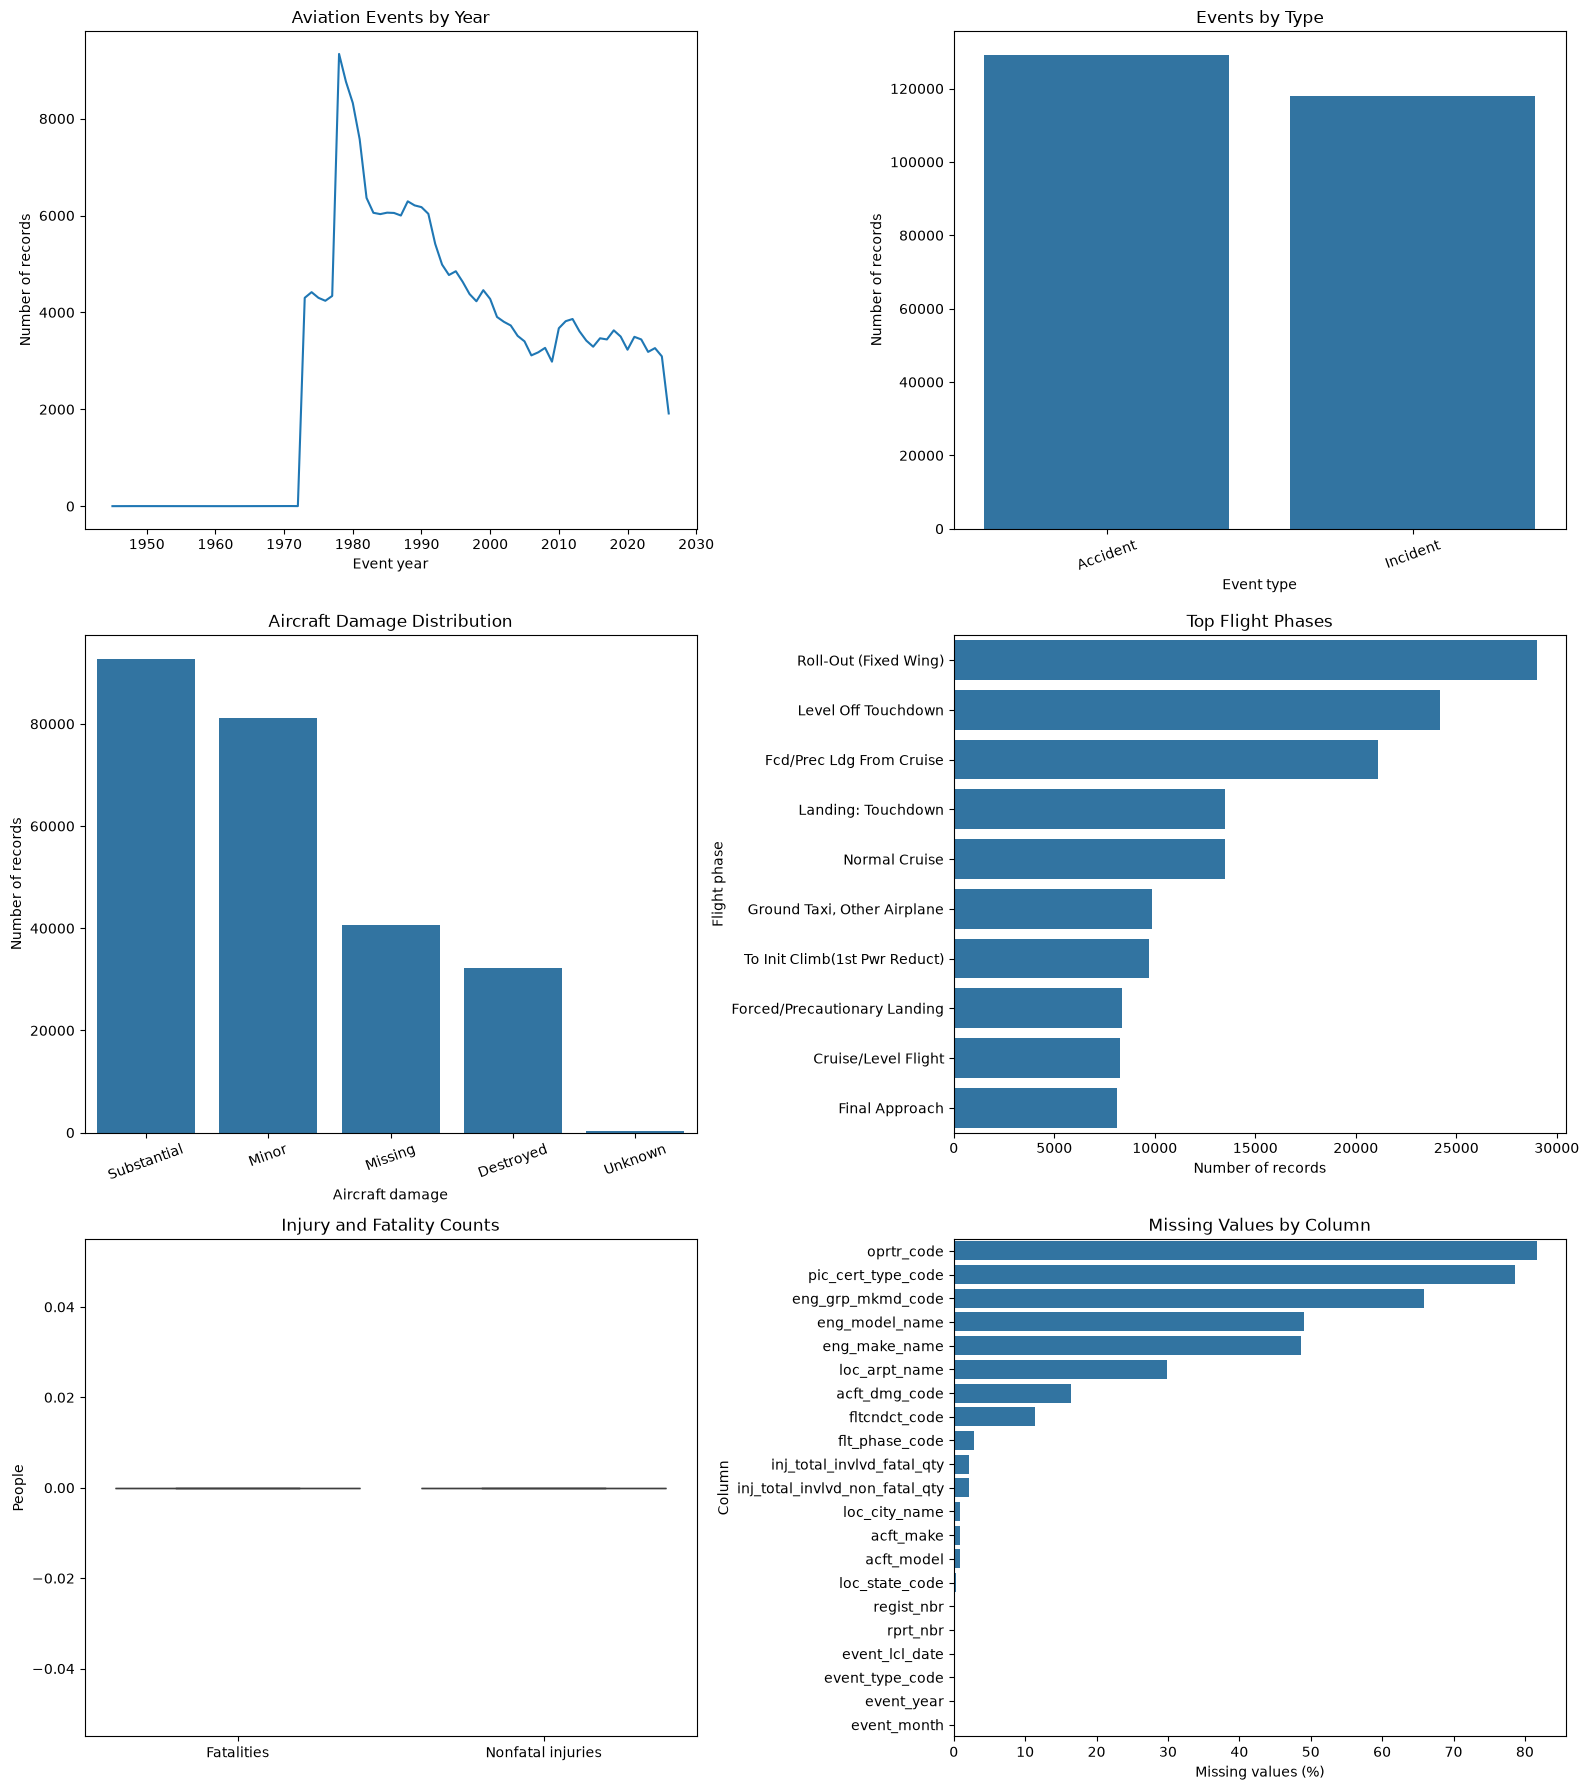

Damage Distribution for the 10 Most Common Flight Phases (%):


acft_dmg_code,Destroyed,Minor,Substantial,Unknown
flt_phase_code,,,,
Cruise/Level Flight,28.49,29.05,42.46,0.00
Fcd/Prec Ldg From Cruise,14.82,26.83,58.16,0.19
Final Approach,17.34,20.23,62.38,0.04
Forced/Precautionary Landing,19.38,19.48,61.06,0.07
"Ground Taxi, Other Airplane",1.03,70.16,28.58,0.23
Landing: Touchdown,2.65,57.81,39.54,0.00
Level Off Touchdown,1.83,67.70,30.42,0.05
Normal Cruise,42.31,33.16,23.90,0.63
Roll-Out (Fixed Wing),1.20,51.86,46.86,0.08


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare analysis-only columns without changing the cleaned working dataframe.
eda_df = df_clean.copy()
eda_df['event_year'] = eda_df['event_lcl_date'].dt.year
eda_df['event_month'] = eda_df['event_lcl_date'].dt.month

plot_df = eda_df.copy()
plot_columns = [
    'event_type_code', 'acft_dmg_code', 'flt_phase_code', 'acft_make'
]
plot_df[plot_columns] = plot_df[plot_columns].fillna('Missing')

print("EDA Dataset Shape:", eda_df.shape)

print("\nEvents by Type:")
display(
    eda_df['event_type_code']
    .value_counts(dropna=False)
    .rename('Count')
    .to_frame()
)

print("\nEvents by Year - Recent Years:")
yearly_events = eda_df['event_year'].value_counts().sort_index().rename('Count').to_frame()
display(yearly_events.tail(15))

print("\nAircraft Damage by Event Type:")
damage_by_event = pd.crosstab(
    eda_df['event_type_code'],
    eda_df['acft_dmg_code'],
    normalize='index'
).mul(100).round(2)
display(damage_by_event)

print("\nTop Flight Phases:")
display(
    eda_df['flt_phase_code']
    .value_counts(dropna=False)
    .head(15)
    .rename('Count')
    .to_frame()
)

print("\nTop Aircraft Makes:")
display(
    eda_df['acft_make']
    .value_counts(dropna=False)
    .head(15)
    .rename('Count')
    .to_frame()
)

print("\nInjury and Fatality Summary:")
display(
    eda_df[
        ['inj_total_invlvd_fatal_qty', 'inj_total_invlvd_non_fatal_qty']
    ].describe().T
)

# Plot key distributions and relationships.
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

sns.lineplot(
    data=yearly_events.reset_index(),
    x='event_year',
    y='Count',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Aviation Events by Year')
axes[0, 0].set_xlabel('Event year')
axes[0, 0].set_ylabel('Number of records')

sns.countplot(
    data=plot_df,
    x='event_type_code',
    order=plot_df['event_type_code'].value_counts().index,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Events by Type')
axes[0, 1].set_xlabel('Event type')
axes[0, 1].set_ylabel('Number of records')
axes[0, 1].tick_params(axis='x', rotation=20)

sns.countplot(
    data=plot_df,
    x='acft_dmg_code',
    order=plot_df['acft_dmg_code'].value_counts().index,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Aircraft Damage Distribution')
axes[1, 0].set_xlabel('Aircraft damage')
axes[1, 0].set_ylabel('Number of records')
axes[1, 0].tick_params(axis='x', rotation=20)

phase_order = plot_df['flt_phase_code'].value_counts().head(10).index
sns.countplot(
    data=plot_df[plot_df['flt_phase_code'].isin(phase_order)],
    y='flt_phase_code',
    order=phase_order,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Top Flight Phases')
axes[1, 1].set_xlabel('Number of records')
axes[1, 1].set_ylabel('Flight phase')

injury_plot_df = eda_df[
    ['inj_total_invlvd_fatal_qty', 'inj_total_invlvd_non_fatal_qty']
].rename(columns={
    'inj_total_invlvd_fatal_qty': 'Fatalities',
    'inj_total_invlvd_non_fatal_qty': 'Nonfatal injuries'
})
sns.boxplot(data=injury_plot_df, ax=axes[2, 0], showfliers=False)
axes[2, 0].set_title('Injury and Fatality Counts')
axes[2, 0].set_ylabel('People')

missing_percentages = (
    eda_df.isna().mean().mul(100).sort_values(ascending=False)
)
sns.barplot(
    x=missing_percentages.values,
    y=missing_percentages.index,
    ax=axes[2, 1]
)
axes[2, 1].set_title('Missing Values by Column')
axes[2, 1].set_xlabel('Missing values (%)')
axes[2, 1].set_ylabel('Column')

plt.tight_layout()
plt.show()

# Focused damage comparison across the most common flight phases.
top_phases = plot_df['flt_phase_code'].value_counts().head(10).index
damage_phase_table = pd.crosstab(
    eda_df.loc[eda_df['flt_phase_code'].isin(top_phases), 'flt_phase_code'],
    eda_df.loc[eda_df['flt_phase_code'].isin(top_phases), 'acft_dmg_code'],
    normalize='index'
).mul(100).round(2)

print("Damage Distribution for the 10 Most Common Flight Phases (%):")
display(damage_phase_table)


# Phase 4: Preprocessing and grouped train/test splitting

This section prepares model-ready datasets without leaking information from the test set. Repeated report numbers are kept together using a grouped 80/20 split. Categorical preprocessing is defined with scikit-learn pipelines and is fitted only on training data during model development.


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Use the Phase 1 feature policy and keep the report number only as a grouping key.
model_feature_columns = feature_columns.copy()

# Build fresh target datasets so Phase 4 can be rerun independently.
phase4_damage_df = damage_model_df[
    model_feature_columns + ['acft_dmg_code', 'rprt_nbr']
].copy()
phase4_fatality_df = fatality_model_df[
    model_feature_columns + ['fatality_class', 'rprt_nbr']
].copy()
phase4_nonfatal_df = nonfatal_model_df[
    model_feature_columns + ['nonfatal_injury_class', 'rprt_nbr']
].copy()

# Nullable integer targets must be converted to ordinary integers for scikit-learn.
phase4_fatality_df['fatality_class'] = phase4_fatality_df['fatality_class'].astype(int)
phase4_nonfatal_df['nonfatal_injury_class'] = (
    phase4_nonfatal_df['nonfatal_injury_class'].astype(int)
)

# Define a grouped 80/20 split for each target.
group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

def make_grouped_split(dataframe, target_column):
    X = dataframe[model_feature_columns].copy()
    y = dataframe[target_column].copy()
    groups = dataframe['rprt_nbr'].copy()

    train_indices, test_indices = next(
        group_splitter.split(X, y, groups=groups)
    )

    X_train = X.iloc[train_indices].copy()
    X_test = X.iloc[test_indices].copy()
    y_train = y.iloc[train_indices].copy()
    y_test = y.iloc[test_indices].copy()
    groups_train = groups.iloc[train_indices].copy()
    groups_test = groups.iloc[test_indices].copy()

    overlap = set(groups_train).intersection(groups_test)
    if overlap:
        raise ValueError(f'Group leakage detected for {target_column}')

    return {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'groups_train': groups_train,
        'groups_test': groups_test
    }

phase4_splits = {
    'damage': make_grouped_split(phase4_damage_df, 'acft_dmg_code'),
    'fatality': make_grouped_split(phase4_fatality_df, 'fatality_class'),
    'nonfatal_injury': make_grouped_split(
        phase4_nonfatal_df,
        'nonfatal_injury_class'
    )
}

print("Grouped Split Summary:")
for target_name, split in phase4_splits.items():
    print(f"\n{target_name}")
    print("Training rows:", len(split['X_train']))
    print("Testing rows:", len(split['X_test']))
    print("Training reports:", split['groups_train'].nunique())
    print("Testing reports:", split['groups_test'].nunique())
    print(
        "Overlapping reports:",
        len(set(split['groups_train']).intersection(split['groups_test']))
    )
    print("Training target distribution:")
    display(split['y_train'].value_counts(normalize=True).mul(100).round(2).rename('Percent').to_frame())
    print("Testing target distribution:")
    display(split['y_test'].value_counts(normalize=True).mul(100).round(2).rename('Percent').to_frame())

# Define reusable preprocessing for categorical features.
# It is intentionally not fitted here; model pipelines will fit it on training data only.
categorical_preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            Pipeline([
                ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
                ('onehot', OneHotEncoder(
                    handle_unknown='ignore',
                    min_frequency=5,
                    sparse_output=True
                ))
            ]),
            model_feature_columns
        )
    ],
    remainder='drop'
)

scaled_categorical_preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            Pipeline([
                ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
                ('onehot', OneHotEncoder(
                    handle_unknown='ignore',
                    min_frequency=5,
                    sparse_output=True
                )),
                ('scale', StandardScaler(with_mean=False))
            ]),
            model_feature_columns
        )
    ],
    remainder='drop'
)

# Fit only on the damage training data as a leakage check.
damage_preprocessor_check = scaled_categorical_preprocessor.fit(
    phase4_splits['damage']['X_train']
)
damage_train_transformed = damage_preprocessor_check.transform(
    phase4_splits['damage']['X_train']
)
damage_test_transformed = damage_preprocessor_check.transform(
    phase4_splits['damage']['X_test']
)

print("\nPreprocessing Check:")
print("Transformed damage training shape:", damage_train_transformed.shape)
print("Transformed damage testing shape:", damage_test_transformed.shape)
print("Preprocessor fitted using training data only: True")


Grouped Split Summary:

damage
Training rows: 164765
Testing rows: 41340
Training reports: 153728
Testing reports: 38432
Overlapping reports: 0
Training target distribution:


,Percent
acft_dmg_code,
Substantial,44.98
Minor,39.35
Destroyed,15.67


Testing target distribution:


,Percent
acft_dmg_code,
Substantial,45.00
Minor,39.34
Destroyed,15.66



fatality
Training rows: 193309
Testing rows: 48372
Training reports: 180088


Testing reports: 45023
Overlapping reports: 0
Training target distribution:


... (6 outputs left out)

,Percent
nonfatal_injury_class,
0,96.01
1,3.99


Testing target distribution:


,Percent
nonfatal_injury_class,
0,95.83
1,4.17



Preprocessing Check:
Transformed damage training shape: (164765, 3369)
Transformed damage testing shape: (41340, 3369)
Preprocessor fitted using training data only: True
